# 03 — Timing, robustness and synthesis

**Question.** How early is divergence supported, which findings survive plausible restrictions, and how do trajectories relate to feature-family performance?

**Cohort.** Use the balanced/available matched trajectories from notebook 02 and the fixed model family definitions from notebook 01. Sensitivities address uncertain episodes, final-week information, role, historical baseline strength, prior injuries and period changes. They do not manufacture clinical onset dates or infer recovery from roster return.

In [1]:
from pathlib import Path
import sys
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'config/injury_signals.yaml').exists())
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
from src.injury_analysis.signals_common import CFG,OUT,CACHE,inputs,read_table
from src.injury_analysis.common import conclusion
from src.injury_analysis import signal_plots as plots
pd.set_option('display.max_columns',16)


## Quantify shape without forcing breakpoints
One event contributes a paired slope/contrast: linear slope across five outings, final-two minus first-two mean, last-outing minus previous-two mean, and late-versus-early slope change. Calendar slopes use actual irregular days and require at least three distinct dates spanning an earlier ≥30-day observation and a last observation ≤14 days before the event.

For z-score features, maximum absolute departure and the fraction of outings beyond |z|≥1 describe heterogeneity/persistence; this reference is **not a clinical abnormality threshold**. No breakpoint is forced from five irregular observations. Timing separately reports isolated supported points and two adjacent same-direction simultaneous intervals excluding zero, requiring ≥30 balanced events. An isolated point does not establish onset, and support at the earliest point can predate the observed window.

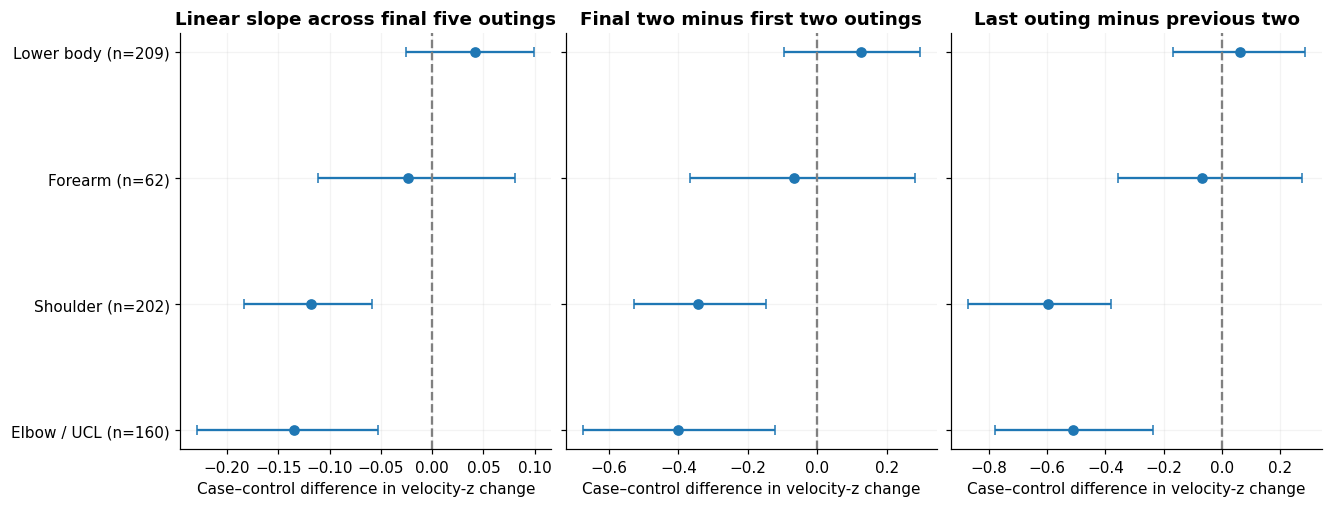

,category,metric,mean,low,high,events
129,Elbow / UCL,absolute_z_ge_1_fraction,0.016250,-0.041676,0.071586,160
130,Elbow / UCL,final_step_vs_previous_two,-0.510304,-0.780143,-0.237267,160
131,Elbow / UCL,late_minus_early_mean,-0.399803,-0.674856,-0.123352,160
132,Elbow / UCL,late_minus_early_slope,-0.253231,-0.503286,0.052279,160
133,Elbow / UCL,maximum_absolute_departure,0.066174,-0.134485,0.233610,160
134,Elbow / UCL,slope_per_10_days,-0.020408,-0.101564,0.046840,129
135,Elbow / UCL,slope_per_appearance,-0.134417,-0.228881,-0.053176,160
282,Forearm,absolute_z_ge_1_fraction,-0.012903,-0.108197,0.098468,62
283,Forearm,final_step_vs_previous_two,-0.068823,-0.356478,0.273305,62
284,Forearm,late_minus_early_mean,-0.066973,-0.367252,0.280658,62


,mode,category,balanced_events,individually_supported_points,first_sustained_point
0,calendar,Elbow / UCL,99,NaN,NaN
1,calendar,Forearm,46,NaN,NaN
2,calendar,Hand / wrist,36,NaN,NaN
3,calendar,Lower body,138,NaN,NaN
4,calendar,Other arm,37,NaN,NaN
5,calendar,Shoulder,117,3,NaN
6,calendar,Trunk / neck,105,NaN,NaN
7,appearance,Elbow / UCL,160,4,NaN
8,appearance,Forearm,62,NaN,NaN
9,appearance,Hand / wrist,56,NaN,NaN


In [2]:
from src.injury_analysis.trajectory_shapes import run_trajectory_sensitivity
from src.injury_analysis.family_decomposition import run_predictive_sensitivity
from src.injury_analysis.signal_report import write_synthesis
a,events,spec,matches=inputs()
aligned=pd.read_parquet(CACHE/'expanded_alignment.parquet')
shapes=read_table('trajectory_shape_metrics')
plots.shape_figure();plt.show()
display(shapes.query("feature=='velo_z'")[['category','metric','mean','low','high','events']])
timing=read_table('trajectory_supported_timing')
display(timing.query("feature=='velo_z'")[['mode','category','balanced_events','individually_supported_points','first_sustained_point']])

## Targeted sensitivity checks
Strict QA does not redefine the primary cohort; it tests dependence on unresolved flags. Removing final 3 or 7 days retains the original event/pseudo-event anchors and does not reindex earlier outings as the last outing. Same-pair contrasts separately address attrition. Strong baseline means ≥15 measured prior observations for the corresponding z-score, not merely long career experience.

First/prior episode uses the as-of reported IL count, not lifetime injury status. Starter/reliever strata use the matched index-outing role. Explicit throwing-side analysis requires known side for arm injuries. Period-specific trajectories reveal small samples rather than claiming a fresh validation. The direct arm-minus-non-arm contrast uses shared pitcher bootstrap draws across groups.

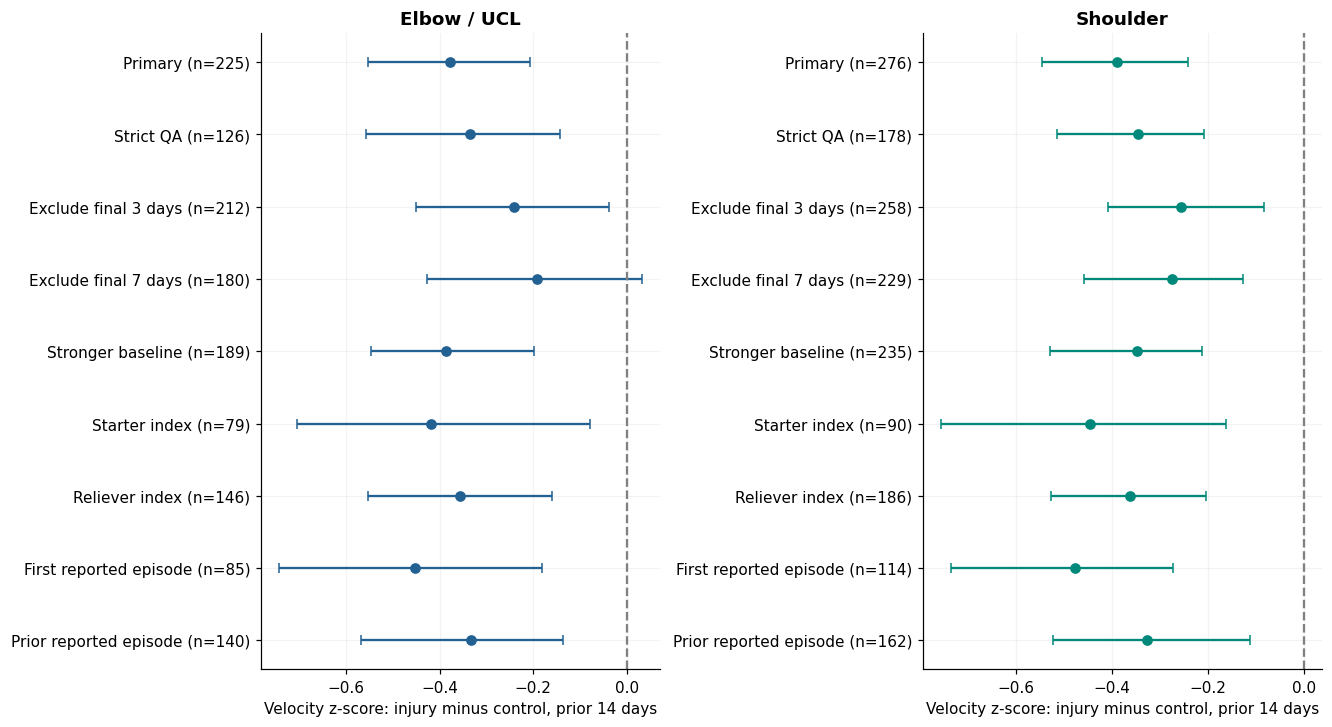

,condition,category,mean,low,high,events
0,Primary,Elbow / UCL,-0.377916,-0.553631,-0.206769,225
1,Primary,Forearm,-0.298698,-0.542208,-0.032927,84
2,Primary,Hand / wrist,-0.288796,-0.566156,-0.031679,68
3,Primary,Lower body,-0.157474,-0.314385,0.002093,280
4,Primary,Other arm,-0.081816,-0.356707,0.199160,85
...,...,...,...,...,...,...
86,Test years 2024–2025,Hand / wrist,0.374161,-0.269140,0.972723,9
87,Test years 2024–2025,Lower body,0.091319,-0.398633,0.520188,37
88,Test years 2024–2025,Other arm,0.026350,-0.455239,0.506210,21
89,Test years 2024–2025,Shoulder,-0.749603,-1.113667,-0.371313,46


,feature,condition,category,primary_on_same_pairs,restricted_mean,mean,low,high,events,pitchers
0,velo_z,Exclude final 3 days,Elbow / UCL,-0.330260,-0.241856,0.088404,0.007408,0.169929,212,199
1,velo_z,Exclude final 3 days,Forearm,-0.350344,-0.327464,0.022880,-0.081782,0.150028,79,77
2,velo_z,Exclude final 3 days,Hand / wrist,-0.295908,-0.310585,-0.014677,-0.163243,0.153290,64,61
3,velo_z,Exclude final 3 days,Lower body,-0.163299,-0.130247,0.033051,-0.036311,0.096259,262,223
4,velo_z,Exclude final 3 days,Other arm,-0.025548,0.192638,0.218186,0.081929,0.336394,78,76
5,velo_z,Exclude final 3 days,Shoulder,-0.408667,-0.256127,0.152541,0.077556,0.242152,258,225
6,velo_z,Exclude final 3 days,Trunk / neck,-0.209027,-0.134160,0.074867,-0.017405,0.181750,195,175
7,velo_z,Exclude final 7 days,Elbow / UCL,-0.301866,-0.192070,0.109796,-0.036789,0.244229,180,171
8,velo_z,Exclude final 7 days,Forearm,-0.281038,-0.396174,-0.115136,-0.327927,0.082283,71,69
9,velo_z,Exclude final 7 days,Hand / wrist,-0.244256,-0.161006,0.083250,-0.172133,0.373578,53,51


,feature,arm_events,nonarm_events,arm_mean,nonarm_mean,arm_minus_nonarm,low,high
0,extension_z,655,486,0.037523,-0.004066,0.041589,-0.073230,0.163155
1,fb_velo_sd_change_vs_prev_5,654,486,0.003148,0.022575,-0.019427,-0.064179,0.023172
2,release_z_sd_z,655,486,-0.013176,-0.043013,0.029837,-0.116546,0.161681
3,velo_z,654,486,-0.340126,-0.162464,-0.177662,-0.325626,-0.006473
4,workload_acceleration_7d_vs_21d,645,478,0.077105,-0.164172,0.241277,-0.209642,0.743385


In [3]:
sensitivity=run_trajectory_sensitivity(aligned)
plots.sensitivity_figure();plt.show()
display(sensitivity.query("feature=='velo_z'")[['condition','category','mean','low','high','events']])
display(read_table('trajectory_sensitivity_same_pair_contrasts').query("feature=='velo_z'"))
display(read_table('arm_nonarm_direct_contrasts'))

## Does the predictive conclusion survive timing restrictions?
Refit WH, WH+velocity/mechanics and Full using the same rows under strict QA or excluding all positive appearances in the final six days. Those late rows become excluded, not healthy negatives. Restricting positive definitions changes prevalence, so compare models **within** each sensitivity, not raw AP across cohorts. Frozen model role comparisons reuse the original fitted models.

The 2024–2025 period has already informed this exploration; it is not an untouched final test. Model and trajectory conclusions should be replicated using adjudicated timing and a new held-out period.

In [4]:
refits=run_predictive_sensitivity(a,events,spec)
display(refits[refits.variant.eq('Full')][['category','analysis','rows','represented_events','average_precision','ap_delta','delta_low','delta_high']])
display(read_table('family_role_sensitivity'))
text=write_synthesis()
display(Markdown(text))
v=sensitivity.query("feature=='velo_z' and condition=='Exclude final 7 days'").set_index('category')
conclusion(f"After excluding the final week, the matched shoulder velocity difference is {v.loc['Shoulder','mean']:.3f} (95% interval {v.loc['Shoulder','low']:.3f} to {v.loc['Shoulder','high']:.3f}); elbow/UCL is {v.loc['Elbow / UCL','mean']:.3f} ({v.loc['Elbow / UCL','low']:.3f} to {v.loc['Elbow / UCL','high']:.3f}). These results refine the timing claim and should be read alongside the smaller balanced samples, paired model increments and random-alert reference in the computed synthesis. No single best model or biological onset estimate is selected.")

,category,analysis,rows,represented_events,average_precision,ap_delta,delta_low,delta_high
2,Elbow / UCL,Strict QA,27396,64,0.019625,-0.007272,-0.022744,-0.000087
5,Elbow / UCL,Exclude final 6 days,27477,104,0.028751,-0.003867,-0.020275,0.011639
8,Shoulder,Strict QA,27592,90,0.060371,0.013089,0.000475,0.031482
11,Shoulder,Exclude final 6 days,27581,116,0.033916,-0.001675,-0.010478,0.003951
14,Forearm,Strict QA,27183,30,0.016780,0.006613,-0.000746,0.024543
17,Forearm,Exclude final 6 days,27167,36,0.016130,0.007870,0.001239,0.020341
20,Lower body,Strict QA,27494,85,0.039023,-0.000269,-0.005011,0.004846
23,Lower body,Exclude final 6 days,27413,92,0.035213,0.001411,-0.001873,0.012020


,category,role,variant,rows,positive_rows,events,ap_delta,delta_low,delta_high,average_precision,roc_auc
0,Elbow / UCL,Starter,Workload + history,6449,235,60,0.000000,0.000000,0.000000,0.066818,0.633665
1,Elbow / UCL,Starter,WH + velocity + mechanics,6449,235,60,-0.006508,-0.023723,0.009283,0.060311,0.599604
2,Elbow / UCL,Starter,Full,6449,235,60,-0.002909,-0.022194,0.017083,0.063909,0.605735
3,Elbow / UCL,Reliever,Workload + history,21216,473,60,0.000000,0.000000,0.000000,0.034521,0.572162
4,Elbow / UCL,Reliever,WH + velocity + mechanics,21216,473,60,0.001867,-0.014965,0.010934,0.036388,0.612920
5,Elbow / UCL,Reliever,Full,21216,473,60,0.002317,-0.022733,0.021064,0.036838,0.621755
6,Forearm,Starter,Workload + history,6288,74,18,0.000000,0.000000,0.000000,0.011339,0.499211
7,Forearm,Starter,WH + velocity + mechanics,6288,74,18,-0.000304,-0.002412,0.001933,0.011035,0.486347
8,Forearm,Starter,Full,6288,74,18,0.000797,-0.002839,0.025359,0.012136,0.469774
9,Forearm,Reliever,Workload + history,20948,205,23,0.000000,0.000000,0.000000,0.012586,0.587770


# Feature-family decomposition and pre-injury trajectory shape

## Scope and design

This extends the existing analysis without changing the database, original cohort, labels, historical features, or 1,225 matched pairs. It compares 18 family/combination specifications across seven injury categories at the 30-day horizon. The original train-through-2021 / validation-2022–2023 / test-2024–2025 boundaries and 60-day embargo are retained. The 2024–2025 period was already examined: these are **exploratory temporal comparisons**, not a new untouched confirmatory test.

All models use the same fixed regularized logistic framework and category-specific rows, with training-only imputation/scaling. A separate common-row modern study adds arm angle using training from 2020–2021. Small modern categories are explicitly skipped. Current-outing features are known after the outing. Labels describe recorded injury/IL-date proxies, not verified biological onset.

## 1. Which information carries signal?

The following are the top two *individual-family validation point estimates* for inspection, not statistically established winners:

| category     | variant         |   average_precision |   pr_lift |
|:-------------|:----------------|--------------------:|----------:|
| Elbow / UCL  | pitcher_history |              0.0419 |    1.8717 |
| Lower body   | workload        |              0.0408 |    1.2365 |
| Lower body   | pitch_mix       |              0.0395 |    1.1979 |
| Shoulder     | workload        |              0.0374 |    1.3697 |
| Shoulder     | extension       |              0.0370 |    1.3527 |
| Trunk / neck | pitcher_history |              0.0333 |    1.3172 |
| Trunk / neck | spin_movement   |              0.0300 |    1.1859 |
| Elbow / UCL  | velocity        |              0.0279 |    1.2438 |
| Forearm      | extension       |              0.0142 |    1.3379 |
| Forearm      | workload        |              0.0140 |    1.3167 |
| Hand / wrist | pitcher_history |              0.0132 |    1.9953 |
| Hand / wrist | workload        |              0.0126 |    1.8971 |
| Other arm    | pitcher_history |              0.0122 |    1.4184 |
| Other arm    | extension       |              0.0102 |    1.1927 |

The full model's incremental AP over workload + history is:

| category     |   workload_history_test_ap |   full_test_ap |   ap_delta |   delta_low |   delta_high |   validation_full_ap_delta |
|:-------------|---------------------------:|---------------:|-----------:|------------:|-------------:|---------------------------:|
| Elbow / UCL  |                     0.0450 |         0.0432 |    -0.0018 |     -0.0161 |       0.0128 |                    -0.0029 |
| Shoulder     |                     0.0507 |         0.0565 |     0.0058 |     -0.0033 |       0.0159 |                     0.0067 |
| Forearm      |                     0.0120 |         0.0215 |     0.0094 |      0.0016 |       0.0233 |                    -0.0004 |
| Other arm    |                     0.0151 |         0.0101 |    -0.0050 |     -0.0227 |      -0.0001 |                    -0.0053 |
| Trunk / neck |                     0.0290 |         0.0276 |    -0.0015 |     -0.0132 |       0.0052 |                     0.0020 |
| Lower body   |                     0.0472 |         0.0475 |     0.0003 |     -0.0045 |       0.0083 |                     0.0013 |
| Hand / wrist |                     0.0138 |         0.0091 |    -0.0046 |     -0.0147 |      -0.0003 |                    -0.0055 |

Full-model AP is higher by point estimate in 3/7 validation categories and 3/7 test categories. Paired pitcher-bootstrap intervals and the different results across periods are more informative than choosing the largest score. The observed intervals condition on the fitted models; they do not include refitting uncertainty or multiple-comparison adjustment.

Workload/history already explains much of the ranking information. For elbow/UCL the full-minus-baseline test AP difference is -0.0018; for shoulder it is +0.0058; for lower body +0.0003. Forearm has a test difference of +0.0094 but a validation difference of -0.0004, which limits a stable injury-specific interpretation.

Selected variable inspection within the strongest validation families:

| category    | family          | feature                   |   mean |
|:------------|:----------------|:--------------------------|-------:|
| Shoulder    | workload        | season_pitch_count        | 0.0080 |
| Shoulder    | workload        | innings_pitched           | 0.0066 |
| Shoulder    | workload        | starter_share_prev_5      | 0.0031 |
| Elbow / UCL | pitcher_history | observed_prior_mlb_starts | 0.0027 |
| Elbow / UCL | pitcher_history | days_since_mlb_debut      | 0.0026 |
| Shoulder    | workload        | rest_days                 | 0.0025 |
| Lower body  | workload        | innings_pitched           | 0.0024 |
| Elbow / UCL | pitcher_history | calendar_month            | 0.0022 |
| Elbow / UCL | velocity        | velo_z                    | 0.0022 |
| Lower body  | pitch_mix       | sl_usage_pct              | 0.0020 |
| Lower body  | workload        | appearances_prev_14d      | 0.0013 |
| Lower body  | workload        | season_pitch_count        | 0.0012 |
| Forearm     | extension       | extension_avg             | 0.0006 |
| Forearm     | workload        | innings_pitched           | 0.0006 |
| Forearm     | workload        | acute_chronic_pitch_ratio | 0.0005 |
| Forearm     | workload        | starts_prev_30d           | 0.0004 |

Permutation occurs within validation season/role strata, with five shuffles. These are conditional AP losses within the full model, not causal effects. Correlation can distribute importance across variables. The displayed shuffle variability is not a sampling confidence interval. The role indicator is held fixed by the shuffle design and is therefore assessed only through its coefficient/family models.

## 2. General versus throwing-arm-specific signals

Workload/context signal appears in both arm and non-arm comparisons. The incremental modeling results do not establish consistent arm-specific added value from velocity/mechanics. Models compare each injury category against an IL-free pool; they do not directly classify arm versus non-arm injury.

The direct matched 1–14-day velocity contrast is stronger in explicitly throwing-side cases: arm minus non-arm difference -0.178 z-units (exploratory 95% interval -0.326 to -0.006; 654 arm and 486 non-arm pairs). Both groups have negative matched velocity differences. This pooled descriptive contrast is not a validated injury-specific prediction rule and is not adjusted for the many feature comparisons.

Modern arm-angle incremental results on identical rows:

| category     |   average_precision |   ap_delta |   delta_low |   delta_high |
|:-------------|--------------------:|-----------:|------------:|-------------:|
| Elbow / UCL  |              0.0352 |    -0.0015 |     -0.0042 |       0.0006 |
| Shoulder     |              0.0370 |     0.0004 |     -0.0007 |       0.0023 |
| Trunk / neck |              0.0314 |    -0.0005 |     -0.0072 |       0.0047 |
| Lower body   |              0.0346 |    -0.0017 |     -0.0078 |      -0.0001 |
| Hand / wrist |              0.0079 |     0.0002 |     -0.0004 |       0.0038 |

These compare with a full model *without* arm angle on the same shorter-era cohort, not with the long-history full model. The short 2020–2021 training period and missing-angle selection limit inference.

## 3. What do the trajectories look like?

Balanced analyses keep the same matched events at every calendar bin or every one of the final five appearances, separately for each feature. Available-pair curves and attrition tables remain available. No smoothing or interpolation hides support.

Velocity's excess final step (last outing minus previous two, case change minus control change) is:

| category     |   mean |    low |   high |   events |    q10 |   q90 |
|:-------------|-------:|-------:|-------:|---------:|-------:|------:|
| Elbow / UCL  | -0.510 | -0.780 | -0.237 |  160.000 | -2.847 | 1.696 |
| Forearm      | -0.069 | -0.356 |  0.273 |   62.000 | -2.079 | 1.486 |
| Hand / wrist | -0.334 | -0.827 |  0.078 |   56.000 | -2.642 | 1.861 |
| Lower body   |  0.062 | -0.167 |  0.285 |  209.000 | -2.151 | 2.305 |
| Other arm    | -0.377 | -0.879 |  0.096 |   60.000 | -2.863 | 2.044 |
| Shoulder     | -0.597 | -0.871 | -0.382 |  202.000 | -3.031 | 1.571 |
| Trunk / neck | -0.095 | -0.378 |  0.218 |  148.000 | -2.462 | 2.606 |

Elbow/UCL has an excess final step of -0.510 z-units; shoulder -0.597; lower body 0.062. These contrasts, slopes and trajectory plots distinguish late changes from sustained early divergence. Event-specific changes span wide distributions: a group mean is not an individual warning threshold.

Pitcher baseline speed, season workload and recent role can differ well before the event, helping models rank persistent profiles without a strong mean approach-to-injury trajectory. The heterogeneity figure displays this distinction. The existing logistic baseline cannot establish nonlinear mechanisms; no biological mechanism is inferred from coefficient or curve shape.

## 4. How early is there evidence of change?

Timing uses simultaneous bootstrap bands across points **within a feature/category** and at least 30 balanced events. We separately report isolated supported points and two adjacent, same-direction supported points. Bands are not adjusted across all features/categories. The velocity timing results are:

| mode       | category     |   balanced_events | individually_supported_points   |   first_sustained_point |
|:-----------|:-------------|------------------:|:--------------------------------|------------------------:|
| calendar   | Elbow / UCL  |                99 | nan                             |                     nan |
| calendar   | Forearm      |                46 | nan                             |                     nan |
| calendar   | Hand / wrist |                36 | nan                             |                     nan |
| calendar   | Lower body   |               138 | nan                             |                     nan |
| calendar   | Other arm    |                37 | nan                             |                     nan |
| calendar   | Shoulder     |               117 | 3                               |                     nan |
| calendar   | Trunk / neck |               105 | nan                             |                     nan |
| appearance | Elbow / UCL  |               160 | 4                               |                     nan |
| appearance | Forearm      |                62 | nan                             |                     nan |
| appearance | Hand / wrist |                56 | nan                             |                     nan |
| appearance | Lower body   |               209 | nan                             |                     nan |
| appearance | Other arm    |                60 | nan                             |                     nan |
| appearance | Shoulder     |               202 | 0;4                             |                     nan |
| appearance | Trunk / neck |               148 | nan                             |                     nan |

Calendar point 0=31–60d, 1=15–30d, 2=8–14d, 3=1–7d. Appearance point 0=5th-last and 4=last. An isolated earlier point is not an estimated onset. Support already at point 0 means the change may predate the observed window. Irregular, sparse histories do not justify a forced breakpoint model.

The final-appearance signal cannot be equated with a fixed day lead; actual lead-day distributions are in `velocity_appearance_calendar_support.csv`. The balanced samples are smaller and selected for sustained recent pitching, so compare them with the available-pair and sensitivity results rather than declaring a precise universal warning time.

## 5. What survives the sensitivity checks?

Excluding the final seven days leaves these velocity contrasts over days 8–14:

| category     |   mean |    low |   high |   events |
|:-------------|-------:|-------:|-------:|---------:|
| Elbow / UCL  | -0.192 | -0.428 |  0.032 |  180.000 |
| Forearm      | -0.396 | -0.757 | -0.082 |   71.000 |
| Hand / wrist | -0.161 | -0.577 |  0.293 |   53.000 |
| Lower body   | -0.132 | -0.348 |  0.092 |  233.000 |
| Other arm    |  0.216 | -0.176 |  0.576 |   66.000 |
| Shoulder     | -0.274 | -0.459 | -0.127 |  229.000 |
| Trunk / neck | -0.162 | -0.392 |  0.125 |  168.000 |

The shoulder estimate is -0.274 (interval -0.459 to -0.127); elbow/UCL is -0.192 (interval -0.428 to 0.032). Same-pair contrasts distinguish removal of late observations from changes in which events remain. Strict QA, starter/reliever, first/prior reported injury, stronger measured baseline, throwing-side evidence, and period-specific results are tabulated. First means first observed report, not first lifetime injury.

The predictive refits remove final-six-day positives rather than relabeling them negative. They compare the full and simpler models on the same restricted rows. Strict-QA results have a changed prevalence. Frozen role-specific evaluations assess ranking differences only and do not assign unobserved event roles.

## 6. Practical warning and remaining uncertainty

At the retrospective 5% budget, all-event warning recall and random expectations are:

| category     | variant            |   qualifying_events |   injury_event_recall |   random_expected_event_recall |   median_warning_lead_days |   non_actionable_alerts_per_pitcher_season |
|:-------------|:-------------------|--------------------:|----------------------:|-------------------------------:|---------------------------:|-------------------------------------------:|
| Elbow / UCL  | Workload + history |                 145 |                 0.234 |                          0.157 |                     18.000 |                                      1.101 |
| Elbow / UCL  | Full               |                 145 |                 0.172 |                          0.157 |                     17.000 |                                      1.113 |
| Shoulder     | Workload + history |                 161 |                 0.155 |                          0.170 |                     22.000 |                                      1.112 |
| Shoulder     | Full               |                 161 |                 0.180 |                          0.170 |                     18.000 |                                      1.117 |
| Forearm      | Workload + history |                  46 |                 0.109 |                          0.196 |                     26.000 |                                      1.150 |
| Forearm      | Full               |                  46 |                 0.174 |                          0.196 |                     26.500 |                                      1.124 |
| Other arm    | Workload + history |                  45 |                 0.178 |                          0.184 |                     23.500 |                                      1.134 |
| Other arm    | Full               |                  45 |                 0.089 |                          0.184 |                     27.500 |                                      1.143 |
| Trunk / neck | Workload + history |                  85 |                 0.188 |                          0.174 |                     26.500 |                                      1.107 |
| Trunk / neck | Full               |                  85 |                 0.188 |                          0.174 |                     22.000 |                                      1.118 |
| Lower body   | Workload + history |                 125 |                 0.216 |                          0.162 |                     24.000 |                                      1.095 |
| Lower body   | Full               |                 125 |                 0.224 |                          0.162 |                     24.500 |                                      1.101 |
| Hand / wrist | Workload + history |                  33 |                 0.273 |                          0.174 |                     15.000 |                                      1.136 |
| Hand / wrist | Full               |                  33 |                 0.212 |                          0.174 |                     12.000 |                                      1.143 |

Event recall requires at least seven days of warning. All qualifying events remain in the denominator, including those with no observable warning outing; observable-event recall is separately saved. Uniform-random expected recall accounts for multiple opportunities per event. Bootstrap event differences condition on the fixed observed alert selections and do not include model training or random-policy realization uncertainty. Lead times are conditional on detection; non-actionable alerts include warnings too late for the seven-day objective.

Major limits remain historical text revisions and unverified publication times; IL dates as outcome proxies; incomplete follow-up and selection of active pitchers; shared controls/case identity across some pairs; multiple exploratory comparisons; small forearm/other-arm samples; and differing calendar versus appearance sampling. Feature importance does not establish causality. Apparent stable profiles and late changes should not be presented as a clinically usable early-warning system.

## Artifacts and next step

Three executed notebooks are in `notebooks/injury_signal_analysis/`. Tables and PNG/PDF figures are in `reports/injury_signal_analysis/`; separate analysis Parquet is in `data/injury/analysis/signal_analysis/`. Original notebooks and central DuckDB are preserved.

The next substantive step is prospective-style date adjudication and a prespecified replication of the simplest context/workload baseline versus a small set of additional velocity features, with an actionable lead-time target. Use a new evaluation period for confirmation after these exploratory comparisons.


**Computed conclusion.** After excluding the final week, the matched shoulder velocity difference is -0.274 (95% interval -0.459 to -0.127); elbow/UCL is -0.192 (-0.428 to 0.032). These results refine the timing claim and should be read alongside the smaller balanced samples, paired model increments and random-alert reference in the computed synthesis. No single best model or biological onset estimate is selected.